In [1]:
# Importing Google Drive
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Importing Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [5]:
# Define Dataset Path
file_path = '/content/drive/MyDrive/NLP_Project/Dataset/McDonald_s_Reviews.csv'

In [7]:
# Importing Data Set
df = pd.read_csv(file_path, encoding='cp1252')

# Display Dataset
df.head()

,reviewer_id,store_name,category,store_address,latitude,longitude,rating_count,review_time,review,rating
0,1,McDonald's,Fast food restaurant,"13749 US-183 Hwy, Austin, TX 78750, United States",30.460718,-97.792874,"1,240",3 months ago,Why does it look like someone spit on my food?...,1 star
1,2,McDonald's,Fast food restaurant,"13749 US-183 Hwy, Austin, TX 78750, United States",30.460718,-97.792874,"1,240",5 days ago,It'd McDonalds. It is what it is as far as the...,4 stars
2,3,McDonald's,Fast food restaurant,"13749 US-183 Hwy, Austin, TX 78750, United States",30.460718,-97.792874,"1,240",5 days ago,Made a mobile order got to the speaker and che...,1 star
3,4,McDonald's,Fast food restaurant,"13749 US-183 Hwy, Austin, TX 78750, United States",30.460718,-97.792874,"1,240",a month ago,My mc. Crispy chicken sandwich was ï¿½ï¿½ï¿½ï¿...,5 stars
4,5,McDonald's,Fast food restaurant,"13749 US-183 Hwy, Austin, TX 78750, United States",30.460718,-97.792874,"1,240",2 months ago,"I repeat my order 3 times in the drive thru, a...",1 star


In [8]:
# Check Dataset Shape
print(df.shape)

(33396, 10)


In [9]:
# Check Column Names
print(df.columns)

Index(['reviewer_id', 'store_name', 'category', 'store_address', 'latitude ',
       'longitude', 'rating_count', 'review_time', 'review', 'rating'],
      dtype='object')


In [10]:
# Check Dataset Information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33396 entries, 0 to 33395
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   reviewer_id    33396 non-null  int64  
 1   store_name     33396 non-null  object 
 2   category       33396 non-null  object 
 3   store_address  33396 non-null  object 
 4   latitude       32736 non-null  float64
 5   longitude      32736 non-null  float64
 6   rating_count   33396 non-null  object 
 7   review_time    33396 non-null  object 
 8   review         33396 non-null  object 
 9   rating         33396 non-null  object 
dtypes: float64(2), int64(1), object(7)
memory usage: 2.5+ MB


In [11]:
# Display Dataset
df.head(10)

,reviewer_id,store_name,category,store_address,latitude,longitude,rating_count,review_time,review,rating
0,1,McDonald's,Fast food restaurant,"13749 US-183 Hwy, Austin, TX 78750, United States",30.460718,-97.792874,"1,240",3 months ago,Why does it look like someone spit on my food?...,1 star
1,2,McDonald's,Fast food restaurant,"13749 US-183 Hwy, Austin, TX 78750, United States",30.460718,-97.792874,"1,240",5 days ago,It'd McDonalds. It is what it is as far as the...,4 stars
2,3,McDonald's,Fast food restaurant,"13749 US-183 Hwy, Austin, TX 78750, United States",30.460718,-97.792874,"1,240",5 days ago,Made a mobile order got to the speaker and che...,1 star
3,4,McDonald's,Fast food restaurant,"13749 US-183 Hwy, Austin, TX 78750, United States",30.460718,-97.792874,"1,240",a month ago,My mc. Crispy chicken sandwich was ï¿½ï¿½ï¿½ï¿...,5 stars
4,5,McDonald's,Fast food restaurant,"13749 US-183 Hwy, Austin, TX 78750, United States",30.460718,-97.792874,"1,240",2 months ago,"I repeat my order 3 times in the drive thru, a...",1 star
5,6,McDonald's,Fast food restaurant,"13749 US-183 Hwy, Austin, TX 78750, United States",30.460718,-97.792874,"1,240",3 weeks ago,I work for door dash and they locked us all ou...,1 star
6,7,McDonald's,Fast food restaurant,"13749 US-183 Hwy, Austin, TX 78750, United States",30.460718,-97.792874,"1,240",3 months ago,If I could give this location a zero on custo...,1 star
7,8,McDonald's,Fast food restaurant,"13749 US-183 Hwy, Austin, TX 78750, United States",30.460718,-97.792874,"1,240",a year ago,Came in and ordered a Large coffee w/no ice. T...,1 star
8,9,McDonald's,Fast food restaurant,"13749 US-183 Hwy, Austin, TX 78750, United States",30.460718,-97.792874,"1,240",3 months ago,Went thru drive thru. Ordered. Getting home no...,1 star
9,10,McDonald's,Fast food restaurant,"13749 US-183 Hwy, Austin, TX 78750, United States",30.460718,-97.792874,"1,240",3 months ago,"I'm not really a huge fan of fast food, but I ...",4 stars


In [12]:
# Check Unique Rating Values
print(df['rating'].unique())

['1 star' '4 stars' '5 stars' '2 stars' '3 stars']


In [13]:
# Check Rating Distribution
y_train_1 = pd.DataFrame(df['rating'])

y_train_1.value_counts()

,count
rating,
5 stars,10274
1 star,9431
4 stars,5787
3 stars,4818
2 stars,3086


In [14]:
# Check Missing Values
df.isnull().sum()

,0
reviewer_id,0
store_name,0
category,0
store_address,0
latitude,660
longitude,660
rating_count,0
review_time,0
review,0
rating,0


In [15]:
# Check Duplicate Records
df.duplicated().sum()

np.int64(0)

# Understand customer reviews

In [16]:
# Display Sample Reviews
df[['review', 'rating']].sample(10, random_state=42)

,review,rating
28477,Somehow they forgot to give us our order...no ...,2 stars
20807,Neutral,3 stars
23801,Drive thru a little slow but friendly people a...,5 stars
4534,Normal McDonald's not much else to say,3 stars
27250,Good service,5 stars
866,I went through the drive-through and ordered a...,1 star
30348,Stopped in here on January 24th 2018 and order...,3 stars
25313,Really enjoyed my breakfast ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½...,4 stars
7729,Neutral,3 stars
28389,Terrible..An Employee name Andrea has the wors...,1 star


# Check review length

In [17]:
# Check Review Length
df['review_length'] = df['review'].apply(len)

# Display Review Length
df['review_length'].describe()

,review_length
count,33396.000000
mean,125.903042
std,184.000878
min,1.000000
25%,17.000000
50%,63.000000
75%,160.000000
max,3115.000000


# Visualize review length distribution

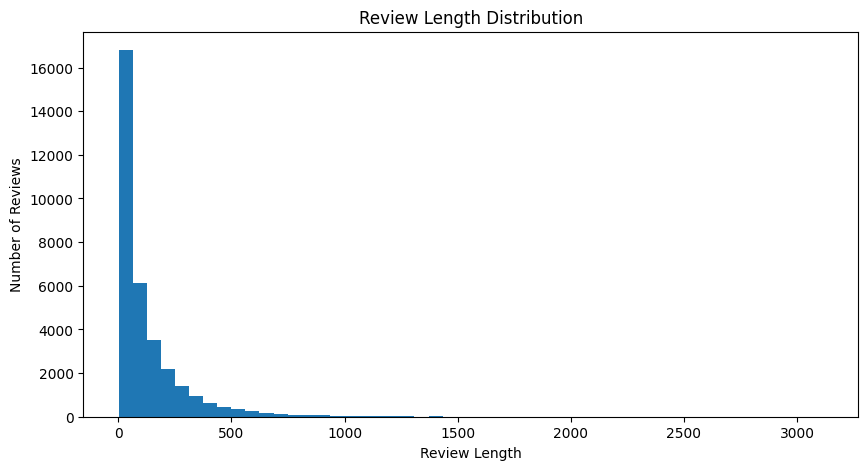

In [18]:
# Visualize Review Length Distribution
plt.figure(figsize=(10, 5))

plt.hist(df['review_length'], bins=50)

plt.title('Review Length Distribution')
plt.xlabel('Review Length')
plt.ylabel('Number of Reviews')

plt.show()

# Check average word count

In [19]:
# Check Word Count
df['word_count'] = df['review'].apply(lambda x: len(x.split()))

# Display Word Count
df['word_count'].describe()

,word_count
count,33396.000000
mean,22.096269
std,33.127654
min,1.000000
25%,3.000000
50%,11.000000
75%,28.000000
max,589.000000


# Display longest reviews

In [20]:
# Display Longest Reviews
df[['review', 'review_length']].sort_values(
    by='review_length',
    ascending=False
).head(5)

,review,review_length
27955,I want to apologize to anyone that I recommend...,3115
23021,I want to apologize to anyone that I recommend...,3115
23689,I've been going to this location most of my li...,2841
28803,I've been going to this location most of my li...,2841
8680,PLAN TO BE UNWELCOMED!!! 15 Mar 2020 p.m.\nI e...,2755


# Calculate word-count percentiles

In [21]:
# Check Word Count Percentiles

print("90th Percentile:", df['word_count'].quantile(0.90))
print("95th Percentile:", df['word_count'].quantile(0.95))
print("99th Percentile:", df['word_count'].quantile(0.99))

90th Percentile: 56.0
95th Percentile: 80.0
99th Percentile: 158.0500000000029


# Convert rating labels into numerical values

In [22]:
# Let us convert rating labels into numerical values

rating_mapping = {
    '1 star': 0,
    '2 stars': 1,
    '3 stars': 2,
    '4 stars': 3,
    '5 stars': 4
}

df['rating'] = df['rating'].map(rating_mapping)

# Display Rating Values
print(df['rating'].unique())

# Check Rating Distribution
df['rating'].value_counts().sort_index()

[0 3 4 1 2]


,count
rating,
0,9431
1,3086
2,4818
3,5787
4,10274


In [23]:
# Importing Regular Expression
import re

# Apply Text Cleaning

In [24]:
# Let us apply text cleaning

def clean_text(text):

    # Convert text into lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)

    # Remove HTML tags
    text = re.sub(r'<.*?>', '', text)

    # Remove special characters and numbers
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text


# Apply text cleaning
df['cleaned_review'] = df['review'].apply(clean_text)

# Display Cleaned Reviews
df[['review', 'cleaned_review']].head(10)

,review,cleaned_review
0,Why does it look like someone spit on my food?...,why does it look like someone spit on my food ...
1,It'd McDonalds. It is what it is as far as the...,it d mcdonalds it is what it is as far as the ...
2,Made a mobile order got to the speaker and che...,made a mobile order got to the speaker and che...
3,My mc. Crispy chicken sandwich was ï¿½ï¿½ï¿½ï¿...,my mc crispy chicken sandwich was customer ser...
4,"I repeat my order 3 times in the drive thru, a...",i repeat my order times in the drive thru and ...
5,I work for door dash and they locked us all ou...,i work for door dash and they locked us all ou...
6,If I could give this location a zero on custo...,if i could give this location a zero on custom...
7,Came in and ordered a Large coffee w/no ice. T...,came in and ordered a large coffee w no ice th...
8,Went thru drive thru. Ordered. Getting home no...,went thru drive thru ordered getting home noti...
9,"I'm not really a huge fan of fast food, but I ...",i m not really a huge fan of fast food but i h...


# Replace your text-cleaning cell

In [25]:
# Let us apply text cleaning

def clean_text(text):

    # Convert text into lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)

    # Remove HTML tags
    text = re.sub(r'<.*?>', '', text)

    # Remove special characters and numbers
    text = re.sub(r"[^a-z'\s]", ' ', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text


# Apply text cleaning
df['cleaned_review'] = df['review'].apply(clean_text)

# Display Cleaned Reviews
df[['review', 'cleaned_review']].head(10)

,review,cleaned_review
0,Why does it look like someone spit on my food?...,why does it look like someone spit on my food ...
1,It'd McDonalds. It is what it is as far as the...,it'd mcdonalds it is what it is as far as the ...
2,Made a mobile order got to the speaker and che...,made a mobile order got to the speaker and che...
3,My mc. Crispy chicken sandwich was ï¿½ï¿½ï¿½ï¿...,my mc crispy chicken sandwich was customer ser...
4,"I repeat my order 3 times in the drive thru, a...",i repeat my order times in the drive thru and ...
5,I work for door dash and they locked us all ou...,i work for door dash and they locked us all ou...
6,If I could give this location a zero on custo...,if i could give this location a zero on custom...
7,Came in and ordered a Large coffee w/no ice. T...,came in and ordered a large coffee w no ice th...
8,Went thru drive thru. Ordered. Getting home no...,went thru drive thru ordered getting home noti...
9,"I'm not really a huge fan of fast food, but I ...",i'm not really a huge fan of fast food but i h...


In [26]:
# Display Sample Cleaned Reviews
for i in range(5):
    print("Original Review:", df['review'][i])
    print("Cleaned Review:", df['cleaned_review'][i])
    print()

Original Review: Why does it look like someone spit on my food?
I had a normal transaction,  everyone was chill and polite, but now i dont want to eat this. Im trying not to think about what this milky white/clear substance is all over my food, i d*** sure am not coming back.
Cleaned Review: why does it look like someone spit on my food i had a normal transaction everyone was chill and polite but now i dont want to eat this im trying not to think about what this milky white clear substance is all over my food i d sure am not coming back

Original Review: It'd McDonalds. It is what it is as far as the food and atmosphere go. The staff here does make a difference. They are all friendly, accommodating and always smiling. Makes for a more pleasant experience than many other fast food places.
Cleaned Review: it'd mcdonalds it is what it is as far as the food and atmosphere go the staff here does make a difference they are all friendly accommodating and always smiling makes for a more pleasa

In [27]:
# Display Cleaned Reviews
df[['cleaned_review', 'rating']].sample(10, random_state=42)

,cleaned_review,rating
28477,somehow they forgot to give us our order no bi...,1
20807,neutral,2
23801,drive thru a little slow but friendly people a...,4
4534,normal mcdonald's not much else to say,2
27250,good service,4
866,i went through the drive through and ordered a...,0
30348,stopped in here on january th and ordered at t...,2
25313,really enjoyed my breakfast this morning hot a...,3
7729,neutral,2
28389,terrible an employee name andrea has the worse...,0


In [28]:
# Check Cleaned Review Word Count
df['cleaned_word_count'] = df['cleaned_review'].apply(
    lambda x: len(x.split())
)

# Display Word Count Statistics
df['cleaned_word_count'].describe()

,cleaned_word_count
count,33396.000000
mean,21.888969
std,32.831616
min,0.000000
25%,3.000000
50%,11.000000
75%,28.000000
max,590.000000


In [30]:
# Check Empty Reviews

empty_reviews = (df['cleaned_review'].str.strip() == '').sum()

print("Number of Empty Reviews:", empty_reviews)

Number of Empty Reviews: 50


In [31]:
# Remove Empty Reviews

df = df[df['cleaned_review'].str.strip() != '']

# Reset Index
df = df.reset_index(drop=True)

# Display Dataset Shape
print("Dataset Shape:", df.shape)

Dataset Shape: (33346, 14)


# Split the dataset into training and testing sets.

In [33]:
# Import Train Test Split
from sklearn.model_selection import train_test_split

# Define Input and Output
x = df['cleaned_review']
y = df['rating']

# Split Dataset
x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display Dataset Shapes
print("Training Data:", x_train.shape)
print("Testing Data:", x_test.shape)

Training Data: (26676,)
Testing Data: (6670,)


# TF-IDF + ANN

In [34]:
# Import TF-IDF Vectorizer
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF Vectorizer
tfidf = TfidfVectorizer(
    max_features=2000,
    ngram_range=(1, 2),
    dtype=np.float32
)

# Fit and Transform Training Data
x_train_tfidf = tfidf.fit_transform(x_train)

# Transform Testing Data
x_test_tfidf = tfidf.transform(x_test)

# Display Shapes
print("Training Data Shape:", x_train_tfidf.shape)
print("Testing Data Shape:", x_test_tfidf.shape)

Training Data Shape: (26676, 2000)
Testing Data Shape: (6670, 2000)


# Convert sparse matrices into NumPy arrays

In [35]:
# Convert Sparse Matrix into Dense Array

x_train_tfidf = x_train_tfidf.toarray()
x_test_tfidf = x_test_tfidf.toarray()

# Display Shapes
print("Training Data Shape:", x_train_tfidf.shape)
print("Testing Data Shape:", x_test_tfidf.shape)

Training Data Shape: (26676, 2000)
Testing Data Shape: (6670, 2000)


# Build the ANN model

In [37]:
# Import Required Libraries
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input


In [38]:

# Initialize ANN Model
model = Sequential()

# Input Layer
model.add(Input(shape=(x_train_tfidf.shape[1],)))

# First Hidden Layer
model.add(Dense(units=128, activation='relu'))

# Second Hidden Layer
model.add(Dense(units=64, activation='relu'))

# Output Layer
model.add(Dense(units=5, activation='softmax'))

# Display Model Summary
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 128)            │       256,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 264,709 (1.01 MB)

 Trainable params: 264,709 (1.01 MB)

 Non-trainable params: 0 (0.00 B)

# Compile ANN Model


In [39]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train ANN Model

In [41]:

history = model.fit(
    x_train_tfidf,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/20
667/667 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.6887 - loss: 0.7965 - val_accuracy: 0.6645 - val_loss: 0.8539
Epoch 2/20
667/667 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.7285 - loss: 0.7048 - val_accuracy: 0.6696 - val_loss: 0.8686
Epoch 3/20
667/667 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.7751 - loss: 0.6038 - val_accuracy: 0.6726 - val_loss: 0.8936
Epoch 4/20
667/667 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.8242 - loss: 0.4904 - val_accuracy: 0.6880 - val_loss: 0.9437
Epoch 5/20
667/667 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.8723 - loss: 0.3708 - val_accuracy: 0.6799 - val_loss: 1.0489
Epoch 6/20
667/667 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.9080 - loss: 0.2746 - val_accuracy: 0.6803 - val_loss: 1.1844
Epoch 7/20
667/667 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.9294 - loss: 0.2127 - val_accuracy: 0.6782 - val_loss: 1.3071
Epoch 8/20
667/667 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9386 - loss: 0.1776 - val_accuracy: 0.

# Plot accuracy and loss

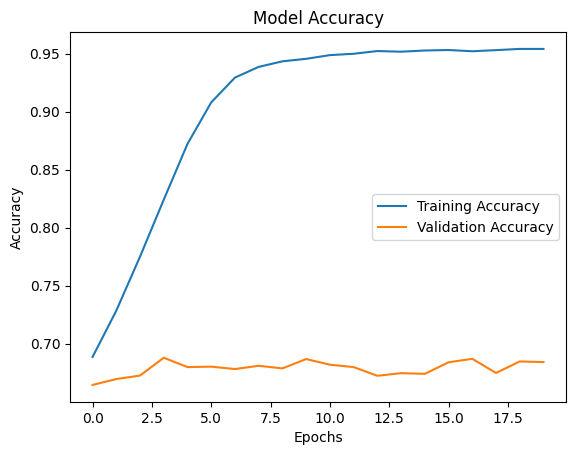

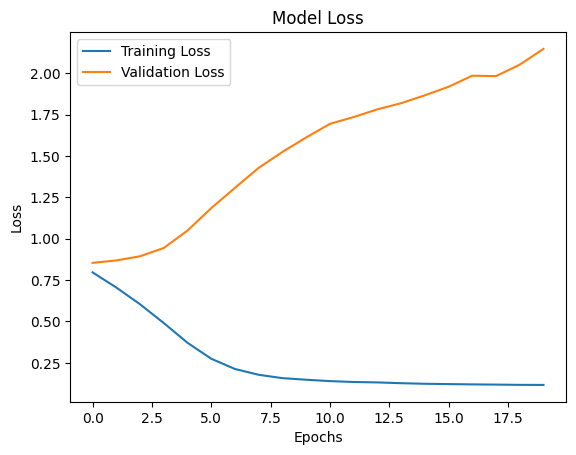

In [42]:
# Plot Training and Validation Accuracy

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(['Training Accuracy', 'Validation Accuracy'])
plt.show()


# Plot Training and Validation Loss

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(['Training Loss', 'Validation Loss'])
plt.show()

# Evaluate ANN Model

In [43]:
test_loss, test_accuracy = model.evaluate(
    x_test_tfidf,
    y_test
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

209/209 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6625 - loss: 2.2180
Test Loss: 2.2179603576660156
Test Accuracy: 0.6625187397003174


# Calculate classification metrics

209/209 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.80      0.78      1886
           1       0.47      0.42      0.44       617
           2       0.58      0.44      0.50       962
           3       0.55      0.52      0.54      1156
           4       0.70      0.79      0.74      2049

    accuracy                           0.66      6670
   macro avg       0.61      0.59      0.60      6670
weighted avg       0.65      0.66      0.66      6670



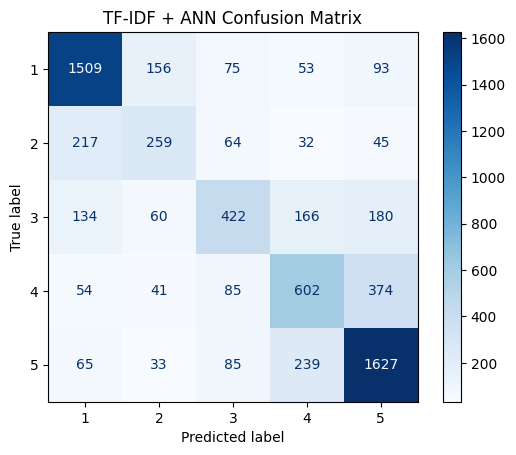

In [44]:
# Import Required Libraries
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Predict Test Data
y_pred = model.predict(x_test_tfidf)

# Convert Probabilities into Class Labels
y_pred = np.argmax(y_pred, axis=1)

# Classification Report
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

# Display Confusion Matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[1, 2, 3, 4, 5]
)

disp.plot(cmap='Blues')
plt.title('TF-IDF + ANN Confusion Matrix')
plt.show()

In [48]:
# Install Optuna
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [optuna]


In [49]:
# Import Required Libraries
import optuna
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.optimizers import Adam, RMSprop

# Define Objective Function

In [50]:
# Define Objective Function

def objective(trial):

    # Clear Previous Model
    from tensorflow.keras import backend as K
    K.clear_session()

    # Select Hyperparameters
    n_layers = trial.suggest_int('n_layers', 1, 3)

    dropout_rate = trial.suggest_float(
        'dropout_rate', 0.1, 0.5
    )

    learning_rate = trial.suggest_float(
        'learning_rate', 0.0001, 0.01, log=True
    )

    optimizer_name = trial.suggest_categorical(
        'optimizer', ['adam', 'rmsprop']
    )

    batch_size = trial.suggest_categorical(
        'batch_size', [32, 64, 128]
    )

    # Initialize ANN Model
    model = Sequential()

    # Input Layer
    model.add(Input(shape=(x_train_tfidf.shape[1],)))

    # Hidden Layers
    for i in range(n_layers):

        units = trial.suggest_int(
            f'units_layer_{i+1}', 64, 256, step=64
        )

        model.add(Dense(units=units, activation='relu'))
        model.add(Dropout(dropout_rate))

    # Output Layer
    model.add(Dense(units=5, activation='softmax'))

    # Select Optimizer
    if optimizer_name == 'adam':
        optimizer = Adam(learning_rate=learning_rate)
    else:
        optimizer = RMSprop(learning_rate=learning_rate)

    # Compile Model
    model.compile(
        optimizer=optimizer,
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    # Train Model
    history = model.fit(
        x_train_tfidf,
        y_train,
        epochs=15,
        batch_size=batch_size,
        validation_split=0.2,
        callbacks=[
            __import__('tensorflow').keras.callbacks.EarlyStopping(
                monitor='val_loss',
                patience=3,
                restore_best_weights=True
            )
        ],
        verbose=0
    )

    # Return Best Validation Accuracy
    return max(history.history['val_accuracy'])

In [51]:
# Create Optuna Study
study = optuna.create_study(
    direction='maximize'
)

# Start Hyperparameter Tuning
study.optimize(
    objective,
    n_trials=20
)

[I 2026-11-25 13:45:30,212] A new study created in memory with name: no-name-f21bb0c6-c23f-442c-bb0b-ece9d66936ea
[I 2026-11-25 13:45:54,189] Trial 0 finished with value: 0.6784107685089111 and parameters: {'n_layers': 3, 'dropout_rate': 0.47693256144006835, 'learning_rate': 0.000585660527800978, 'optimizer': 'adam', 'batch_size': 64, 'units_layer_1': 64, 'units_layer_2': 192, 'units_layer_3': 128}. Best is trial 0 with value: 0.6784107685089111.
[I 2026-11-25 13:46:46,899] Trial 1 finished with value: 0.6709145307540894 and parameters: {'n_layers': 1, 'dropout_rate': 0.17196070571885685, 'learning_rate': 0.00034037638346640363, 'optimizer': 'rmsprop', 'batch_size': 32, 'units_layer_1': 128}. Best is trial 0 with value: 0.6784107685089111.
[I 2026-11-25 13:47:17,645] Trial 2 finished with value: 0.6845952272415161 and parameters: {'n_layers': 2, 'dropout_rate': 0.28653078638359647, 'learning_rate': 0.0006122007394807156, 'optimizer': 'adam', 'batch_size': 64, 'units_layer_1': 256, 'uni

# Build the final tuned ANN

In [52]:
# Clear Previous Model
from tensorflow.keras import backend as K
from tensorflow.keras.callbacks import EarlyStopping

K.clear_session()

# Get Best Hyperparameters
best_params = study.best_params

# Initialize ANN Model
final_model = Sequential()

# Input Layer
final_model.add(Input(shape=(x_train_tfidf.shape[1],)))

# First Hidden Layer
final_model.add(Dense(
    units=best_params['units_layer_1'],
    activation='relu'
))
final_model.add(Dropout(best_params['dropout_rate']))

# Second Hidden Layer
final_model.add(Dense(
    units=best_params['units_layer_2'],
    activation='relu'
))
final_model.add(Dropout(best_params['dropout_rate']))

# Output Layer
final_model.add(Dense(units=5, activation='softmax'))

# Compile Model
final_model.compile(
    optimizer=Adam(learning_rate=best_params['learning_rate']),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Display Model Summary
final_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       512,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 579,333 (2.21 MB)

 Trainable params: 579,333 (2.21 MB)

 Non-trainable params: 0 (0.00 B)

# Train the tuned ANN

In [55]:
# Early Stopping
early_stop = EarlyStopping(
    monitor='val_accuracy',
    mode='max',
    patience=5,
    restore_best_weights=True
)

# Train Final ANN Model
history = final_model.fit(
    x_train_tfidf,
    y_train,
    epochs=30,
    batch_size=best_params['batch_size'],
    validation_split=0.2,
    callbacks=[early_stop]
)

Epoch 1/30
667/667 ━━━━━━━━━━━━━━━━━━━━ 14s 21ms/step - accuracy: 0.8033 - loss: 0.5232 - val_accuracy: 0.6876 - val_loss: 0.9045
Epoch 2/30
667/667 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.8434 - loss: 0.4175 - val_accuracy: 0.6957 - val_loss: 0.9664
Epoch 3/30
667/667 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.8696 - loss: 0.3513 - val_accuracy: 0.7007 - val_loss: 1.0528
Epoch 4/30
667/667 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.8845 - loss: 0.3067 - val_accuracy: 0.6882 - val_loss: 1.1594
Epoch 5/30
667/667 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.9003 - loss: 0.2775 - val_accuracy: 0.6951 - val_loss: 1.2030
Epoch 6/30
667/667 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.9026 - loss: 0.2592 - val_accuracy: 0.6876 - val_loss: 1.2323
Epoch 7/30
667/667 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.9094 - loss: 0.2477 - val_accuracy: 0.6988 - val_loss: 1.2654
Epoch 8/30
667/667 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.9149 - loss: 0.2317 - val_acc

# Evaluate Tuned ANN Model

In [56]:
# Evaluate Tuned ANN Model

test_loss, test_accuracy = final_model.evaluate(
    x_test_tfidf,
    y_test
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

209/209 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.6840 - loss: 1.1335
Test Loss: 1.133473515510559
Test Accuracy: 0.6839579939842224


209/209 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
Tuned ANN Classification Report:
              precision    recall  f1-score   support

           0       0.73      0.87      0.79      1886
           1       0.53      0.39      0.45       617
           2       0.58      0.49      0.54       962
           3       0.61      0.47      0.53      1156
           4       0.73      0.81      0.77      2049

    accuracy                           0.68      6670
   macro avg       0.64      0.61      0.62      6670
weighted avg       0.67      0.68      0.67      6670



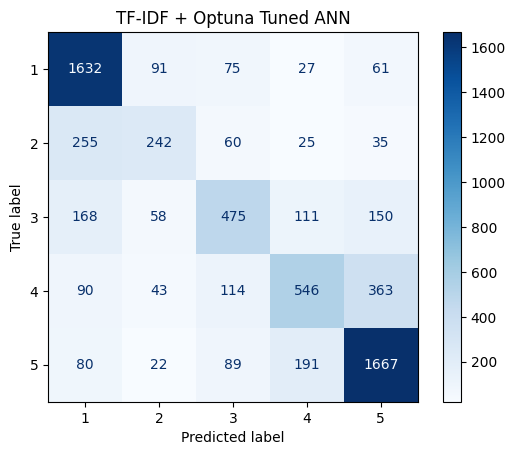

In [57]:
# Import Required Libraries
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Predict Test Data
y_pred_tuned = final_model.predict(x_test_tfidf)

# Convert Probabilities into Class Labels
y_pred_tuned = np.argmax(y_pred_tuned, axis=1)

# Classification Report
print("Tuned ANN Classification Report:")
print(classification_report(y_test, y_pred_tuned))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_tuned)

# Display Confusion Matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[1, 2, 3, 4, 5]
)

disp.plot(cmap='Blues')
plt.title('TF-IDF + Optuna Tuned ANN')
plt.show()

In [58]:
# Save Final Tuned ANN Model

final_model.save(
    project_path + '/final_ann_model.keras'
)

# Save Best Hyperparameters
import json

with open(project_path + '/best_hyperparameters.json', 'w') as f:
    json.dump(best_params, f, indent=4)

print("Final Tuned ANN Model Saved Successfully!")
print("Best Hyperparameters Saved Successfully!")

Final Tuned ANN Model Saved Successfully!
Best Hyperparameters Saved Successfully!


In [59]:
from google.colab import files

files.download(
    project_path + '/final_ann_model.keras'
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [60]:
files.download(
    project_path + '/tfidf_vectorizer.pkl'
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [61]:
files.download(
    project_path + '/best_hyperparameters.json'
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>